# FlashPoint hexagon: spatiotemporal position reconstruction

Adapted from `FlashPoint_spatiotemporal_posreco.ipynb` for the **hexagon-shape detector**.

Main comparison:

1. COG baseline
2. Amplitude Poisson template
3. `A+t1`, `A+t1+t2+t3`, and `A+dN/dt` HGB regression
4. Full spatiotemporal Poisson likelihood
5. `A+t1+t2+t3` ExtraTrees
6. Residuals, $\sigma_x$, $\sigma_y$, $\sigma_{xy}$, $R_{68}$ and $R_{90}$

The notebook automatically infers the number of SiPMs and the sampled hexagon extent from the ROOT file. For a *physical* conventional COG, fill `SIPM_POS_MANUAL`; otherwise the notebook uses training-data response centroids as effective COG positions.


In [18]:
# 0. Imports + configuration
from pathlib import Path
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
from scipy.spatial import ConvexHull
from sklearn.ensemble import HistGradientBoostingRegressor, ExtraTreesRegressor

warnings.filterwarnings("ignore")
SEED=42; rng=np.random.default_rng(SEED)

ROOT=Path("/Volumes/ExtremeSSD/Software/FlashPointHexShape/run/sipm_timing_620p4mm_edge1_20k.root")
FILES=[ROOT]
OUT=ROOT.parent/"sipm_timing_620p4mm_edge1_20k"; OUT.mkdir(parents=True,exist_ok=True)
if not ROOT.exists(): raise FileNotFoundError(ROOT)

# detector timing resolution applied photon-by-photon
APPLY_TIMING_SMEARING=True
TIMING_SIGMA_PS=300       # Gaussian sigma, not FWHM

TRAIN_FRAC=.70
GRID_CELL_MM=25           # template cell size target
MIN_CELL=5
POSTERIOR_K=9
LIKELIHOOD_CHUNK=2000

DT_FINE_NS=.05            # 50 ps master dN/dt bin
EARLY_NS=3.0
DND_REBIN=2               # 100 ps main reconstruction bin
NBIN_FINE=int(round(EARLY_NS/DT_FINE_NS))

HGB_MAX_ITER=180; HGB_LEAVES=31; ML_TRAIN_MAX=100_000
RUN_EXTRA_TREES=True
RUN_TIMING_BIN_SCAN=False
RUN_TRUE_TIMING_SCAN=False

# Optional physical SiPM optical-contact positions, shape=(NSIPM,2), in mm.
# Example: np.array([[x0,y0],[x1,y1],...],float) 

# ==== 400mm
# SIPM_POS_MANUAL=np.array([
#  [ 398.433,   0.000],
#  [ 199.216, 345.053],
#  [-199.216, 345.053],
#  [-398.433,   0.000],
#  [-199.216,-345.053],
#  [ 199.216,-345.053],
#  [ 300.160, 173.298],
#  [   0.000, 346.595],
#  [-300.160, 173.298],
#  [-300.160,-173.298],
#  [   0.000,-346.595],
#  [ 300.160,-173.298],
# ])

# ==== 620.4mm
SIPM_POS_MANUAL=np.array([
 [ 618.833,   0.000],
 [ 309.416, 535.925],
 [-309.416, 535.925],
 [-618.833,   0.000],
 [-309.416,-535.925],
 [ 309.416,-535.925],
 [ 465.460, 268.734],
 [   0.000, 537.467],
 [-465.460, 268.734],
 [-465.460,-268.734],
 [   0.000,-537.467],
 [ 465.460,-268.734],
])


In [19]:
# 1. Inspect ROOT + infer SiPM count
with uproot.open(ROOT) as f:
    print("Trees:",f.keys())
    ek=list(f["events"].keys()); print("events branches:",ek)
    if "hits" in f: print("hits branches:",list(f["hits"].keys()))

ids=sorted(int(m.group(1)) for k in ek if (m:=re.fullmatch(r"n_detected_sipm(\d+)",k)))
if not ids: raise KeyError("No n_detected_sipm{i} branches found")
NSIPM=max(ids)+1
if ids!=list(range(NSIPM)): print("WARNING: non-contiguous SiPM branches:",ids)
print(f"NSIPM={NSIPM}")


Trees: ['hits;1', 'events;1', 'sipm0_time;1', 'sipm1_time;1', 'sipm2_time;1', 'sipm3_time;1', 'sipm4_time;1', 'sipm5_time;1', 'sipm6_time;1', 'sipm7_time;1', 'sipm8_time;1', 'sipm9_time;1', 'sipm10_time;1', 'sipm11_time;1', 'event_counter;1', 'sipm0_path;1', 'sipm1_path;1', 'sipm2_path;1', 'sipm3_path;1', 'sipm4_path;1', 'sipm5_path;1', 'sipm6_path;1', 'sipm7_path;1', 'sipm8_path;1', 'sipm9_path;1', 'sipm10_path;1', 'sipm11_path;1', 'source_xy;1', 'response_sipm0_xy;1', 'response_sipm1_xy;1', 'response_sipm2_xy;1', 'response_sipm3_xy;1', 'response_sipm4_xy;1', 'response_sipm5_xy;1', 'response_sipm6_xy;1', 'response_sipm7_xy;1', 'response_sipm8_xy;1', 'response_sipm9_xy;1', 'response_sipm10_xy;1', 'response_sipm11_xy;1']
events branches: ['event', 'source_x_mm', 'source_y_mm', 'n_produced', 'n_scint_produced', 'n_cherenkov_produced', 'n_reach_sipm0', 'n_reach_sipm1', 'n_reach_sipm2', 'n_reach_sipm3', 'n_reach_sipm4', 'n_reach_sipm5', 'n_reach_sipm6', 'n_reach_sipm7', 'n_reach_sipm8', 'n

In [20]:
# 2. Load events + derive T1/T2/T3 and early dN/dt
TIME_NAMES=["t_plot_ns","t_ns","time_ns","arrival_time_ns","global_time_ns"]
E,T1s,T2s,T3s,DNDs=[],[],[],[],[]
rng_smear=np.random.default_rng(SEED+100)

for job,fname in enumerate(FILES):
    with uproot.open(fname) as f:
        e=f["events"].arrays(library="pd").reset_index(drop=True)
        if "event" not in e: e["event"]=np.arange(len(e))
        e["event"]=e.event.astype(int); ev=e.event.to_numpy(int)

        t1=np.full((len(e),NSIPM),np.nan,np.float32)
        t2=np.full_like(t1,np.nan); t3=np.full_like(t1,np.nan)
        dnd=np.zeros((len(e),NSIPM,NBIN_FINE),np.uint16)

        if "hits" in f:
            hk=set(f["hits"].keys()); thit=next((x for x in TIME_NAMES if x in hk),None)
            if thit is not None:
                h=f["hits"].arrays(["event","sipm",thit],library="pd").reset_index(drop=True)
                h=h.replace([np.inf,-np.inf],np.nan).dropna()
                h["event"]=h.event.astype(int); h["sipm"]=h.sipm.astype(int)
                rowmap=pd.Series(np.arange(len(e)),index=ev)
                h["row"]=h.event.map(rowmap); h=h.dropna(subset=["row"]); h["row"]=h.row.astype(int)
                h=h[(h.sipm>=0)&(h.sipm<NSIPM)]

                h["tm"]=h[thit].to_numpy(float)
                if APPLY_TIMING_SMEARING:
                    h["tm"]+=rng_smear.normal(0,TIMING_SIGMA_PS/1000.,len(h))

                h["dt"]=h.tm-h.groupby("event").tm.transform("min")
                h=h.sort_values(["event","sipm","tm"])
                h["rank"]=h.groupby(["event","sipm"]).cumcount()

                for k,target in [(0,t1),(1,t2),(2,t3)]:
                    z=h[h["rank"]==k]
                    target[z.row.to_numpy(),z.sipm.to_numpy()]=z.dt.to_numpy(np.float32)

                b=np.floor(h.dt.to_numpy()/DT_FINE_NS).astype(int)
                row=h.row.to_numpy(int); sipm=h.sipm.to_numpy(int)
                m=(b>=0)&(b<NBIN_FINE)
                flat=(row[m]*NSIPM+sipm[m])*NBIN_FINE+b[m]
                dnd=np.bincount(flat,minlength=len(e)*NSIPM*NBIN_FINE).reshape(len(e),NSIPM,NBIN_FINE).astype(np.uint16)
            else: print("WARNING: no recognized hit-time branch")
        else: print("WARNING: no hits tree")

        E.append(e); T1s.append(t1); T2s.append(t2); T3s.append(t3); DNDs.append(dnd)
        print(fname.name,"events=",len(e))

events=pd.concat(E,ignore_index=True).replace([np.inf,-np.inf],np.nan)
T1=np.vstack(T1s); T2=np.vstack(T2s); T3=np.vstack(T3s); DND_FINE=np.vstack(DNDs)
print("events:",len(events),"DND_FINE:",DND_FINE.shape)


sipm_timing_620p4mm_edge1_20k.root events= 20000
events: 20000 DND_FINE: (20000, 12, 60)


usable=20,000, train=14,000, test=6,000
truth extent: X=[-612.4,613.7] mm, Y=[-537.2,536.9] mm
reference detector span=1226.0 mm, grid=50x43, mean photons/event=121.5


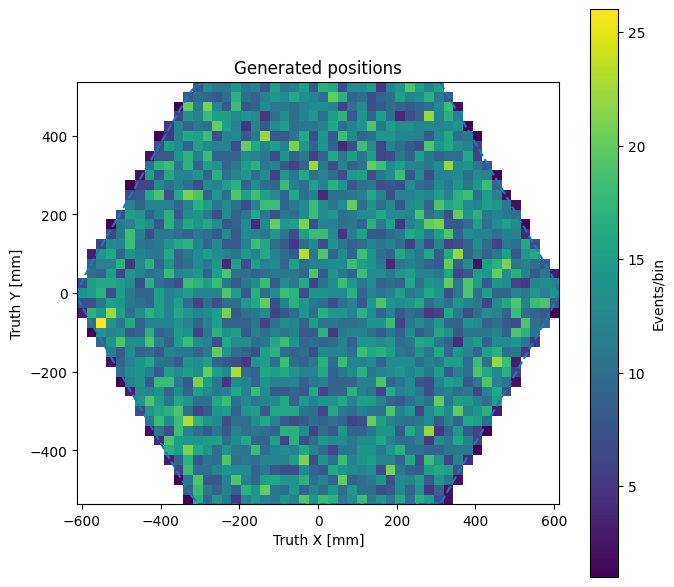

In [21]:
# 3. Truth/amplitude arrays + train/test split + inferred hexagon geometry
def first(df,names): return next((x for x in names if x in df),None)
X=first(events,["source_x_mm","x_source_mm","source_x","x_true_mm"])
Y=first(events,["source_y_mm","y_source_mm","source_y","y_true_mm"])
if X is None or Y is None: raise KeyError("Truth X/Y branches not found")

truth=events[[X,Y]].to_numpy(float)
A=np.column_stack([events[f"n_detected_sipm{i}"].to_numpy(float) for i in range(NSIPM)])
Ntot=A.sum(1)
good=np.isfinite(truth).all(1)&(Ntot>0)
truth,A,T1,T2,T3,DND_FINE=truth[good],A[good],T1[good],T2[good],T3[good],DND_FINE[good]
Ntot=A.sum(1); F=A/Ntot[:,None]; logN=np.log1p(Ntot)[:,None]

idx=rng.permutation(len(truth)); ntr=int(TRAIN_FRAC*len(idx)); itr,ite=idx[:ntr],idx[ntr:]
itr_ml=itr if len(itr)<=ML_TRAIN_MAX else rng.choice(itr,ML_TRAIN_MAX,replace=False)

xmin,xmax=truth[:,0].min(),truth[:,0].max(); ymin,ymax=truth[:,1].min(),truth[:,1].max()
XSPAN=xmax-xmin; YSPAN=ymax-ymin; LREF=max(XSPAN,YSPAN)
NX=max(10,int(np.ceil(XSPAN/GRID_CELL_MM))); NY=max(10,int(np.ceil(YSPAN/GRID_CELL_MM)))
XED=np.linspace(xmin,xmax,NX+1); YED=np.linspace(ymin,ymax,NY+1)
XC=(XED[:-1]+XED[1:])/2; YC=(YED[:-1]+YED[1:])/2
HULL=truth[ConvexHull(truth).vertices]

print(f"usable={len(truth):,}, train={len(itr):,}, test={len(ite):,}")
print(f"truth extent: X=[{xmin:.1f},{xmax:.1f}] mm, Y=[{ymin:.1f},{ymax:.1f}] mm")
print(f"reference detector span={LREF:.1f} mm, grid={NX}x{NY}, mean photons/event={Ntot.mean():.1f}")

fig,ax=plt.subplots(figsize=(7,6))
h=ax.hist2d(truth[:,0],truth[:,1],bins=[XED,YED],cmin=1)
p=np.vstack([HULL,HULL[0]]); ax.plot(p[:,0],p[:,1],"--",lw=1.5)
ax.set(xlabel="Truth X [mm]",ylabel="Truth Y [mm]",aspect="equal",title="Generated positions")
plt.colorbar(h[3],ax=ax,label="Events/bin")
plt.tight_layout(); plt.show()


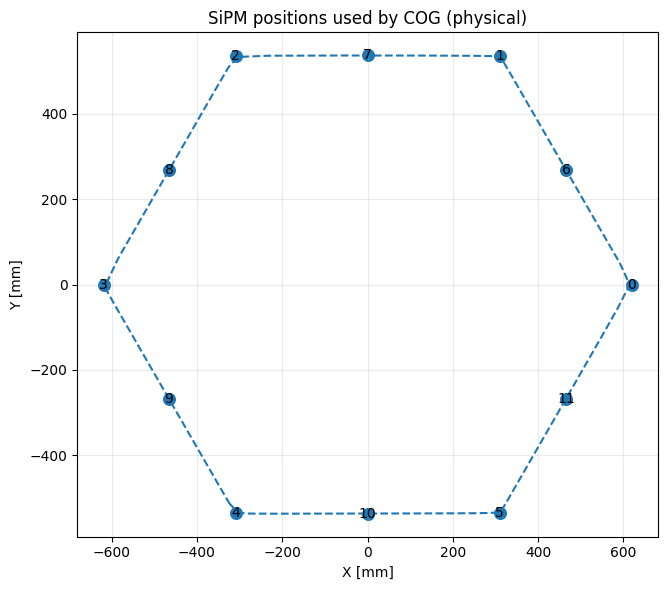

In [22]:
# 4. SiPM positions for COG: physical positions if supplied, otherwise effective response centroids
if SIPM_POS_MANUAL is not None:
    POS=np.asarray(SIPM_POS_MANUAL,float)
    assert POS.shape==(NSIPM,2)
    POS_KIND="physical"
else:
    w=A[itr]
    den=w.sum(0)
    POS=np.column_stack([(w*truth[itr,0,None]).sum(0)/den,(w*truth[itr,1,None]).sum(0)/den])
    POS_KIND="effective response-centroid"

fig,ax=plt.subplots(figsize=(7,6))
h=np.vstack([HULL,HULL[0]]); ax.plot(h[:,0],h[:,1],"--",lw=1.5)
ax.scatter(POS[:,0],POS[:,1],s=70)
for i,(x,y) in enumerate(POS): ax.text(x,y,str(i),ha="center",va="center",fontsize=10)
ax.set(xlabel="X [mm]",ylabel="Y [mm]",aspect="equal",title=f"SiPM positions used by COG ({POS_KIND})")
ax.grid(alpha=.25); plt.tight_layout(); plt.show()


In [23]:
# 5. dN/dt rebin + metrics / plotting helpers
def rebin_dnd(dnd,factor):
    if factor==1: return dnd
    n=(dnd.shape[2]//factor)*factor
    return dnd[:,:,:n].reshape(len(dnd),NSIPM,n//factor,factor).sum(3)

DND=rebin_dnd(DND_FINE,DND_REBIN); DT_MAIN_NS=DT_FINE_NS*DND_REBIN

def metrics(name,xy):
    m=np.isfinite(xy).all(1); d=xy[m]-truth[ite][m]
    dx,dy=d[:,0],d[:,1]; r=np.hypot(dx,dy); sx,sy=dx.std(),dy.std()
    return dict(method=name,N=m.sum(),bias_x_mm=dx.mean(),bias_y_mm=dy.mean(),
                sigma_x_mm=sx,sigma_y_mm=sy,sigma_xy_mm=np.sqrt((sx*sx+sy*sy)/2),
                R68_mm=np.quantile(r,.68),R90_mm=np.quantile(r,.90))

def performance(name,xy,bins=60):
    tru=truth[ite]; m=np.isfinite(xy).all(1); tru,rec=tru[m],xy[m]
    dx,dy=(rec-tru).T; rr=np.hypot(dx,dy)
    fig,ax=plt.subplots(2,2,figsize=(10,8))
    for a,j,l,lo,hi in [(ax[0,0],0,"X",xmin,xmax),(ax[0,1],1,"Y",ymin,ymax)]:
        hh=a.hist2d(tru[:,j],rec[:,j],bins=bins,range=[[lo,hi],[lo,hi]])
        a.plot([lo,hi],[lo,hi],"--",lw=1); a.set(xlabel=f"Truth {l} [mm]",ylabel=f"Reco {l} [mm]")
        plt.colorbar(hh[3],ax=a,label="Events / bin")
    q=max(np.quantile(np.abs(np.r_[dx,dy]),.995),1)
    ax[1,0].hist(dx,100,range=(-q,q),histtype="step",density=True,label=fr"X $\sigma$={dx.std():.1f} mm")
    ax[1,0].hist(dy,100,range=(-q,q),histtype="step",density=True,label=fr"Y $\sigma$={dy.std():.1f} mm")
    ax[1,0].set(xlabel="Reco - truth [mm]",ylabel="Density"); ax[1,0].legend()
    rs=np.sort(rr); ax[1,1].plot(rs,np.arange(1,len(rs)+1)/len(rs)); ax[1,1].axhline(.68,ls="--"); ax[1,1].axhline(.90,ls="--")
    ax[1,1].set(xlabel="Radial error [mm]",ylabel="CDF",title=f"R68={np.quantile(rr,.68):.1f}, R90={np.quantile(rr,.90):.1f} mm")
    fig.suptitle(name); plt.tight_layout(); plt.show()


In [24]:
# 6. COG baseline
pred={}
def cog(Ax,pos):
    s=Ax.sum(1); out=np.full((len(Ax),2),np.nan); m=s>0
    out[m]=Ax[m]@pos/s[m,None]; return out

pred[f"COG ({POS_KIND})"]=cog(A[ite],POS)
display(pd.DataFrame([metrics(k,v) for k,v in pred.items()]).round(2))


,method,N,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,COG (physical),6000,2.85,-0.42,199.84,197.78,198.81,310.32,392.81


## Amplitude template likelihood

The hexagon is embedded in a rectangular calibration grid, but only cells populated by training events are retained. Thus cells outside the detector automatically disappear from the likelihood template.


In [25]:
# 7. Regular templates + Poisson reconstruction
def build_templates(Z,indices=itr):
    xy=truth[indices]
    ix=np.clip(np.digitize(xy[:,0],XED)-1,0,NX-1); iy=np.clip(np.digitize(xy[:,1],YED)-1,0,NY-1)
    gid=iy*NX+ix; count=np.bincount(gid,minlength=NX*NY)
    sums=np.zeros((NX*NY,Z.shape[1]),float); np.add.at(sums,gid,Z[indices])
    mu=np.divide(sums,count[:,None],out=np.full_like(sums,np.nan),where=count[:,None]>0)
    gy,gx=np.divmod(np.arange(NX*NY),NX); pos=np.column_stack([XC[gx],YC[gy]])
    valid=count>=MIN_CELL
    return pos[valid],mu[valid],count.reshape(NY,NX),mu.reshape(NY,NX,-1)

def poisson_reco(Zq,pos,mu,k=POSTERIOR_K,chunk=LIKELIHOOD_CHUNK):
    mu=np.clip(mu,1e-6,None); logmu=np.log(mu); musum=mu.sum(1); out=np.empty((len(Zq),2))
    for s in range(0,len(Zq),chunk):
        q=np.asarray(Zq[s:s+chunk],float); score=musum[None,:]-q@logmu.T
        kk=min(k,score.shape[1]); ii=np.argpartition(score,kk-1,axis=1)[:,:kk]
        ss=np.take_along_axis(score,ii,axis=1); ss-=ss.min(1,keepdims=True); w=np.exp(-ss)
        out[s:s+len(q)]=(w[:,:,None]*pos[ii]).sum(1)/w.sum(1)[:,None]
    return out

posA,muA,countA,muAgrid=build_templates(A)
pred["Amplitude Poisson template"]=poisson_reco(A[ite],posA,muA)
print("valid amplitude-template cells:",len(posA))
display(pd.DataFrame([metrics("Amplitude Poisson template",pred["Amplitude Poisson template"])]).round(2))


valid amplitude-template cells: 1521


,method,N,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,Amplitude Poisson template,6000,0.64,1.99,87.01,87.3,87.16,105.38,196.76


## Direct nonlinear regression

Amplitude information is represented by per-SiPM fractions plus total detected light; timing uses event-relative first-photon times. This keeps the logic directly comparable to the square-detector notebook.


In [26]:
# 8. HGB: A+t1, A+t1+t2+t3, A+dN/dt
def hgb_xy(Xf):
    med=np.nanmedian(Xf[itr_ml],axis=0); med=np.where(np.isfinite(med),med,0)
    Xf=np.where(np.isfinite(Xf),Xf,med)
    out=np.empty((len(ite),2)); models=[]
    for j in range(2):
        m=HistGradientBoostingRegressor(max_iter=HGB_MAX_ITER,learning_rate=.08,max_leaf_nodes=HGB_LEAVES,
                                       l2_regularization=1.0,random_state=SEED+j)
        m.fit(Xf[itr_ml],truth[itr_ml,j]); out[:,j]=m.predict(Xf[ite]); models.append(m)
    return out,models

Afeat=np.hstack([F,logN])
X_A_T1=np.hstack([Afeat,T1]); X_A_T123=np.hstack([Afeat,T1,T2,T3])
DNDflat=np.log1p(DND.reshape(len(DND),-1).astype(np.float32)); X_A_DND=np.hstack([Afeat,DNDflat])

pred["A + t1 HGB"],_=hgb_xy(X_A_T1)
pred["A + t1+t2+t3 HGB"],_=hgb_xy(X_A_T123)
pred[f"A + dN/dt ({DT_MAIN_NS*1e3:.0f} ps) HGB"],_=hgb_xy(X_A_DND)

display(pd.DataFrame([metrics(k,pred[k]) for k in ["A + t1 HGB","A + t1+t2+t3 HGB",f"A + dN/dt ({DT_MAIN_NS*1e3:.0f} ps) HGB"]]).round(2))


,method,N,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,A + t1 HGB,6000,-0.71,-0.46,51.27,52.44,51.86,74.56,113.18
1,A + t1+t2+t3 HGB,6000,-0.69,-0.73,49.67,50.95,50.31,72.13,109.93
2,A + dN/dt (100 ps) HGB,6000,0.86,0.31,63.02,61.51,62.27,85.30,136.34


In [27]:
# 9. Full binned spatiotemporal Poisson likelihood
early=DND.sum(2).astype(float); late=np.maximum(A-early,0)
K=np.hstack([DND.reshape(len(DND),-1).astype(float),late])
posST,muST,countST,muSTgrid=build_templates(K)
name=f"Full ST Poisson ({DT_MAIN_NS*1e3:.0f} ps)"
pred[name]=poisson_reco(K[ite],posST,muST)
print("valid ST-template cells:",len(posST))
display(pd.DataFrame([metrics(name,pred[name])]).round(2))


valid ST-template cells: 1521


,method,N,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,Full ST Poisson (100 ps),6000,-1.58,-2.18,81.49,83.48,82.49,119.69,185.67


In [28]:
# 10. ExtraTrees main baseline
if RUN_EXTRA_TREES:
    med=np.nanmedian(X_A_T123[itr_ml],axis=0); med=np.where(np.isfinite(med),med,0)
    Ximp=np.where(np.isfinite(X_A_T123),X_A_T123,med)
    model=ExtraTreesRegressor(n_estimators=300,min_samples_leaf=2,max_features=.8,n_jobs=-1,random_state=SEED)
    model.fit(Ximp[itr_ml],truth[itr_ml])
    pred["A + t1+t2+t3 ExtraTrees"]=model.predict(Ximp[ite])
    display(pd.DataFrame([metrics("A + t1+t2+t3 ExtraTrees",pred["A + t1+t2+t3 ExtraTrees"])]).round(2))


,method,N,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm
0,A + t1+t2+t3 ExtraTrees,6000,-0.32,-0.85,46.66,48.35,47.51,66.95,105.16


,method,N,bias_x_mm,bias_y_mm,sigma_x_mm,sigma_y_mm,sigma_xy_mm,R68_mm,R90_mm,sigma_xy_pct,R68_pct,R90_pct
0,A + t1+t2+t3 ExtraTrees,6000,-0.32,-0.85,46.66,48.35,47.51,66.95,105.16,3.88,5.46,8.58
1,A + t1+t2+t3 HGB,6000,-0.69,-0.73,49.67,50.95,50.31,72.13,109.93,4.10,5.88,8.97
2,A + t1 HGB,6000,-0.71,-0.46,51.27,52.44,51.86,74.56,113.18,4.23,6.08,9.23
3,A + dN/dt (100 ps) HGB,6000,0.86,0.31,63.02,61.51,62.27,85.30,136.34,5.08,6.96,11.12
4,Amplitude Poisson template,6000,0.64,1.99,87.01,87.30,87.16,105.38,196.76,7.11,8.60,16.05
5,Full ST Poisson (100 ps),6000,-1.58,-2.18,81.49,83.48,82.49,119.69,185.67,6.73,9.76,15.14
6,COG (physical),6000,2.85,-0.42,199.84,197.78,198.81,310.32,392.81,16.22,25.31,32.04


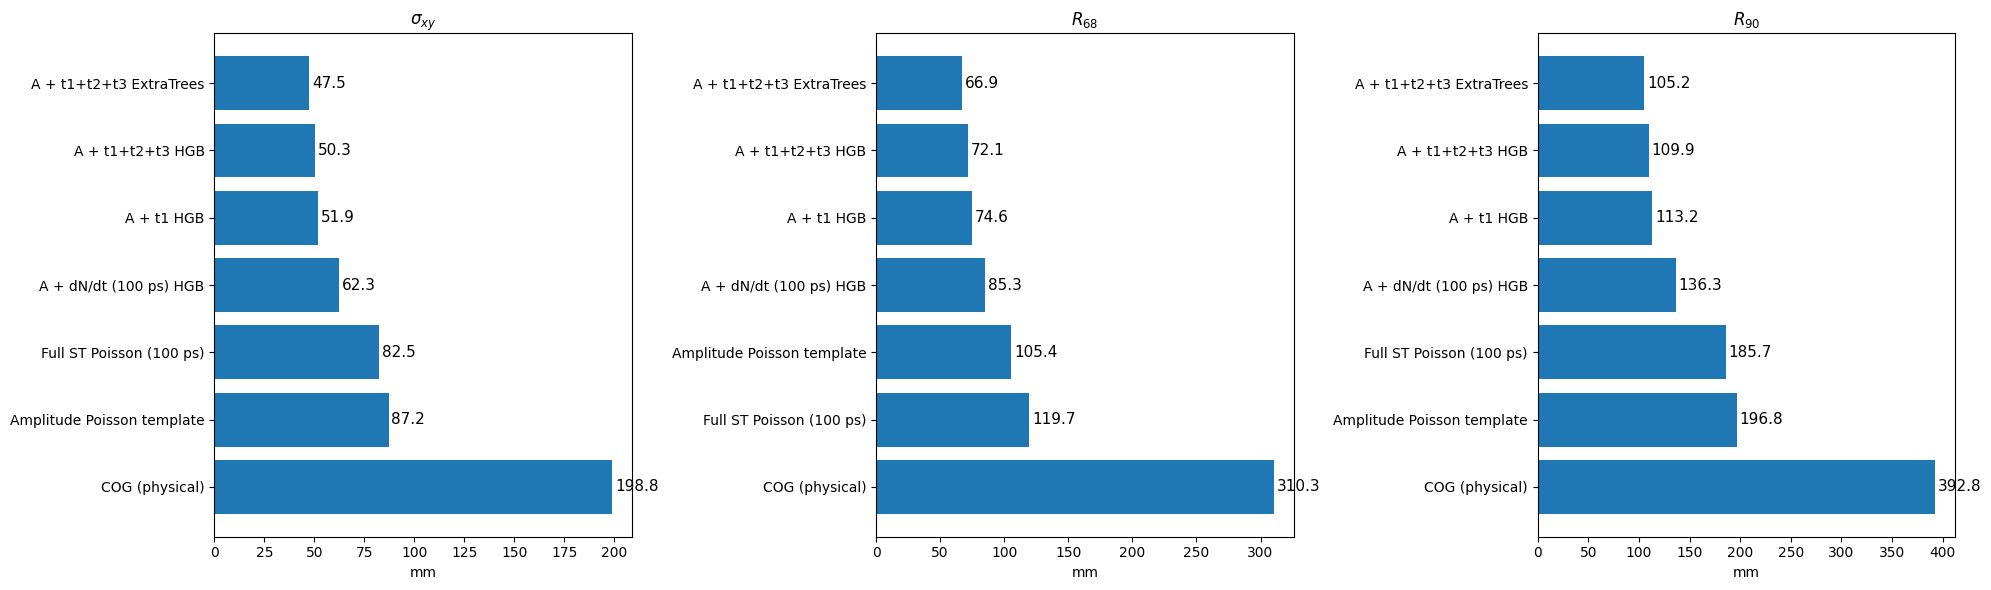

Best by R68: A + t1+t2+t3 ExtraTrees


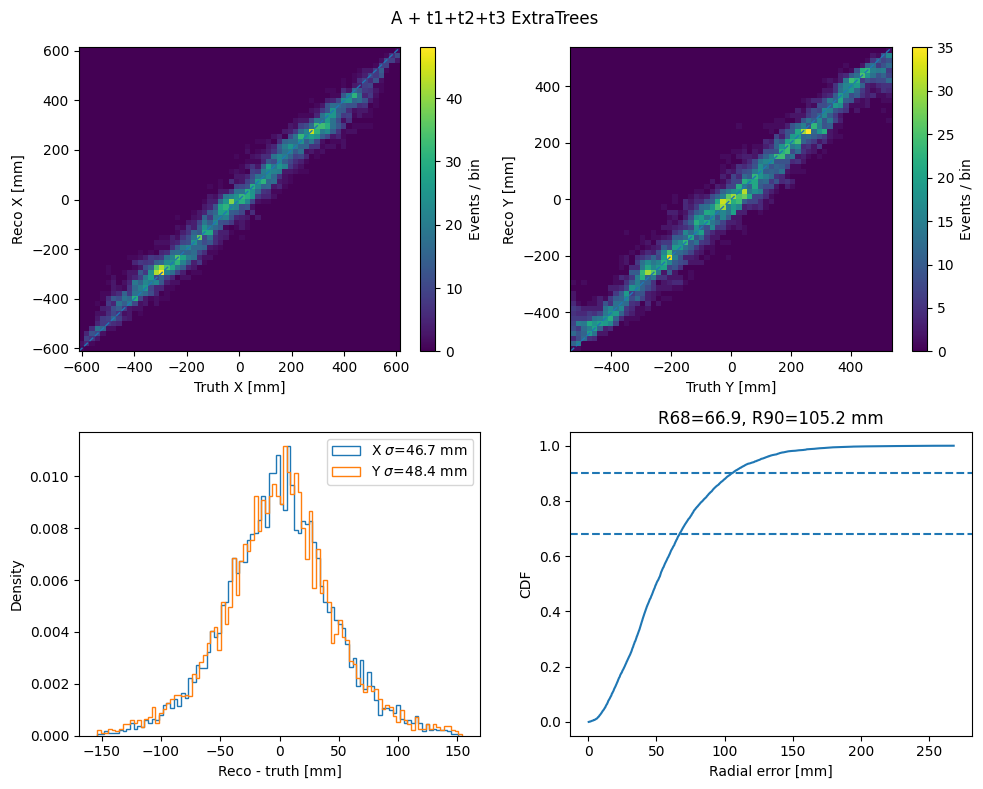

In [29]:
# 11. Final comparison
summary=pd.DataFrame([metrics(k,v) for k,v in pred.items()]).sort_values("R68_mm").reset_index(drop=True)
summary["sigma_xy_pct"]=100*summary.sigma_xy_mm/LREF
summary["R68_pct"]=100*summary.R68_mm/LREF
summary["R90_pct"]=100*summary.R90_mm/LREF
display(summary.round(2))
summary.to_csv(OUT/"hex_position_reconstruction_summary.csv",index=False)

fig,ax=plt.subplots(1,3,figsize=(20,6))
for a,c,t in zip(ax,["sigma_xy_mm","R68_mm","R90_mm"],[r"$\sigma_{xy}$",r"$R_{68}$",r"$R_{90}$"]):
    z=summary.sort_values(c); b=a.barh(z.method,z[c]); a.bar_label(b,fmt="%.1f",padding=2,fontsize=11)
    a.invert_yaxis(); a.set(xlabel="mm",title=t)
plt.tight_layout(); plt.savefig(OUT/"hex_reconstruction_comparison.png",dpi=180,bbox_inches="tight"); plt.show()

best=summary.iloc[0].method
print("Best by R68:",best)
performance(best,pred[best])


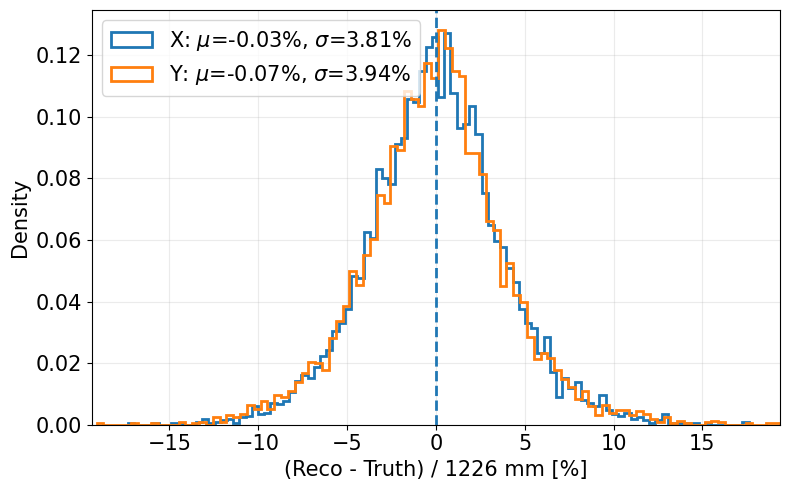

In [30]:
# 12. Relative residual of best method (normalized to maximum sampled detector span)
name=summary.iloc[0].method; xy=pred[name]; tru=truth[ite]
m=np.isfinite(xy).all(1); R=100*(xy[m]-tru[m])/LREF; s=R.std(0).mean()
fig,ax=plt.subplots(figsize=(8,5))
for j,l in enumerate("XY"):
    r=R[:,j]; ax.hist(r,100,histtype="step",density=True,lw=2,label=fr"{l}: $\mu$={r.mean():.2f}%, $\sigma$={r.std():.2f}%")
ax.axvline(0,ls="--",lw=2); ax.set(xlabel=f"(Reco - Truth) / {LREF:.0f} mm [%]",ylabel="Density",xlim=(-5*s,5*s))
ax.tick_params(labelsize=15); ax.xaxis.label.set_size(15); ax.yaxis.label.set_size(15); ax.legend(fontsize=15); ax.grid(alpha=.25)
plt.tight_layout(); plt.savefig(OUT/"hex_resolution_relative.png",dpi=180,bbox_inches="tight"); plt.show()


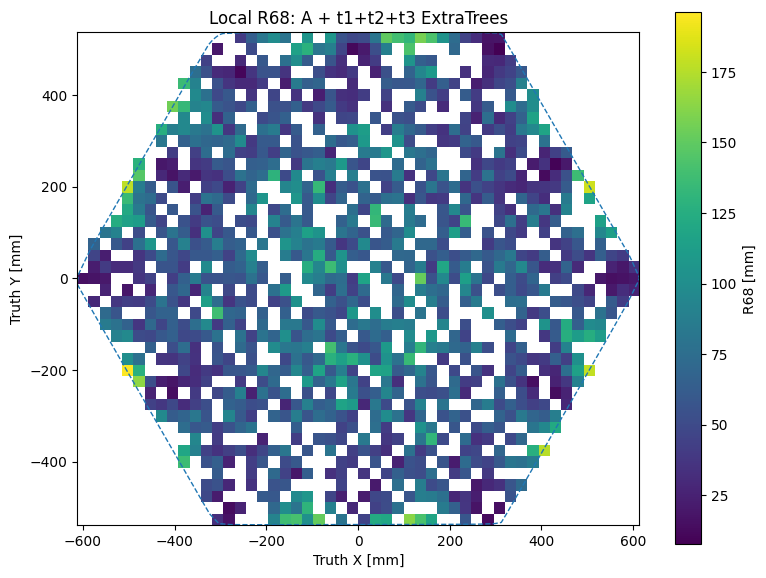

In [31]:
# 13. Spatial resolution map for best method
xy=pred[best]; d=xy-truth[ite]; rr=np.hypot(d[:,0],d[:,1])
ix=np.clip(np.digitize(truth[ite,0],XED)-1,0,NX-1); iy=np.clip(np.digitize(truth[ite,1],YED)-1,0,NY-1)
M=np.full((NY,NX),np.nan)
for g in np.unique(iy*NX+ix):
    q=(iy*NX+ix)==g
    if q.sum()>=3: M[g//NX,g%NX]=np.quantile(rr[q],.68)

fig,ax=plt.subplots(figsize=(8,6))
im=ax.imshow(M,origin="lower",extent=(xmin,xmax,ymin,ymax),aspect="equal")
h=np.vstack([HULL,HULL[0]]); ax.plot(h[:,0],h[:,1],"--",lw=1)
ax.set(xlabel="Truth X [mm]",ylabel="Truth Y [mm]",title=f"Local R68: {best}")
plt.colorbar(im,ax=ax,label="R68 [mm]"); plt.tight_layout(); plt.savefig(OUT/"hex_R68_map.png",dpi=180,bbox_inches="tight"); plt.show()


In [32]:
# 14. Optional dN/dt bin-width scan
if RUN_TIMING_BIN_SCAN:
    scan=[]
    for fac in [1,2,4,6]:
        if NBIN_FINE%fac: continue
        d=rebin_dnd(DND_FINE,fac); late=np.maximum(A-d.sum(2),0); Z=np.hstack([d.reshape(len(d),-1).astype(float),late])
        p,m,_,_=build_templates(Z); xy=poisson_reco(Z[ite],p,m)
        met=metrics(f"{DT_FINE_NS*fac*1e3:.0f} ps",xy); scan.append(met); print(met["method"],f'R68={met["R68_mm"]:.2f} mm')
    scan=pd.DataFrame(scan); display(scan.round(2))


In [33]:
RUN_TRUE_TIMING_SCAN = True
# 15. Optional true detector timing-resolution scan using A+t1+t2+t3 ExtraTrees
SIGMA_T_PS=[0,50,100,150,200,250,300,400,500,750,1000]

def get_T123(sigma_ps):
    rg=np.random.default_rng(SEED+int(sigma_ps)); T=[]
    with uproot.open(ROOT) as f:
        e=f["events"].arrays(["event"],library="pd") if "event" in f["events"].keys() else pd.DataFrame({"event":np.arange(f["events"].num_entries)})
        ev=e.event.to_numpy(int); n=len(e); out=[np.full((n,NSIPM),np.nan,np.float32) for _ in range(3)]
        hk=set(f["hits"].keys()); thit=next((x for x in TIME_NAMES if x in hk),None)
        h=f["hits"].arrays(["event","sipm",thit],library="pd").replace([np.inf,-np.inf],np.nan).dropna()
    h["event"]=h.event.astype(int); h["sipm"]=h.sipm.astype(int); h["row"]=h.event.map(pd.Series(np.arange(n),index=ev)); h=h.dropna(subset=["row"])
    h["row"]=h.row.astype(int); h=h[(h.sipm>=0)&(h.sipm<NSIPM)]; h["tm"]=h[thit].to_numpy(float)+rg.normal(0,sigma_ps/1000.,len(h))
    h["dt"]=h.tm-h.groupby("event").tm.transform("min"); h=h.sort_values(["event","sipm","tm"]); h["rank"]=h.groupby(["event","sipm"]).cumcount()
    for k in range(3):
        z=h[h["rank"]==k]; out[k][z.row.to_numpy(),z.sipm.to_numpy()]=z.dt.to_numpy(np.float32)
    return [x[good] for x in out]

if RUN_TRUE_TIMING_SCAN:
    S=[]
    for sig in SIGMA_T_PS:
        t1,t2,t3=get_T123(sig); Xf=np.hstack([Afeat,t1,t2,t3]); med=np.nanmedian(Xf[itr_ml],0); med=np.where(np.isfinite(med),med,0); Xf=np.where(np.isfinite(Xf),Xf,med)
        model=ExtraTreesRegressor(n_estimators=300,min_samples_leaf=2,max_features=.8,n_jobs=-1,random_state=SEED)
        model.fit(Xf[itr_ml],truth[itr_ml]); met=metrics(f"{sig} ps",model.predict(Xf[ite])); met["sigma_t_ps"]=sig; S.append(met)
        print(f'{sig:4d} ps: sigma_xy={met["sigma_xy_mm"]:.2f} mm, R68={met["R68_mm"]:.2f} mm')
    S=pd.DataFrame(S); display(S[["sigma_t_ps","sigma_xy_mm","R68_mm","R90_mm"]].round(2))


   0 ps: sigma_xy=44.07 mm, R68=62.37 mm
  50 ps: sigma_xy=44.18 mm, R68=62.28 mm
 100 ps: sigma_xy=44.71 mm, R68=63.45 mm
 150 ps: sigma_xy=45.19 mm, R68=64.11 mm
 200 ps: sigma_xy=45.90 mm, R68=65.17 mm
 250 ps: sigma_xy=47.08 mm, R68=66.47 mm
 300 ps: sigma_xy=47.45 mm, R68=67.64 mm
 400 ps: sigma_xy=49.03 mm, R68=70.16 mm
 500 ps: sigma_xy=50.32 mm, R68=71.25 mm
 750 ps: sigma_xy=54.22 mm, R68=77.34 mm
1000 ps: sigma_xy=57.14 mm, R68=80.58 mm


,sigma_t_ps,sigma_xy_mm,R68_mm,R90_mm
0,0,44.07,62.37,97.43
1,50,44.18,62.28,97.77
2,100,44.71,63.45,99.10
3,150,45.19,64.11,99.77
4,200,45.90,65.17,100.73
5,250,47.08,66.47,104.54
6,300,47.45,67.64,105.26
7,400,49.03,70.16,107.76
8,500,50.32,71.25,110.36
9,750,54.22,77.34,118.64


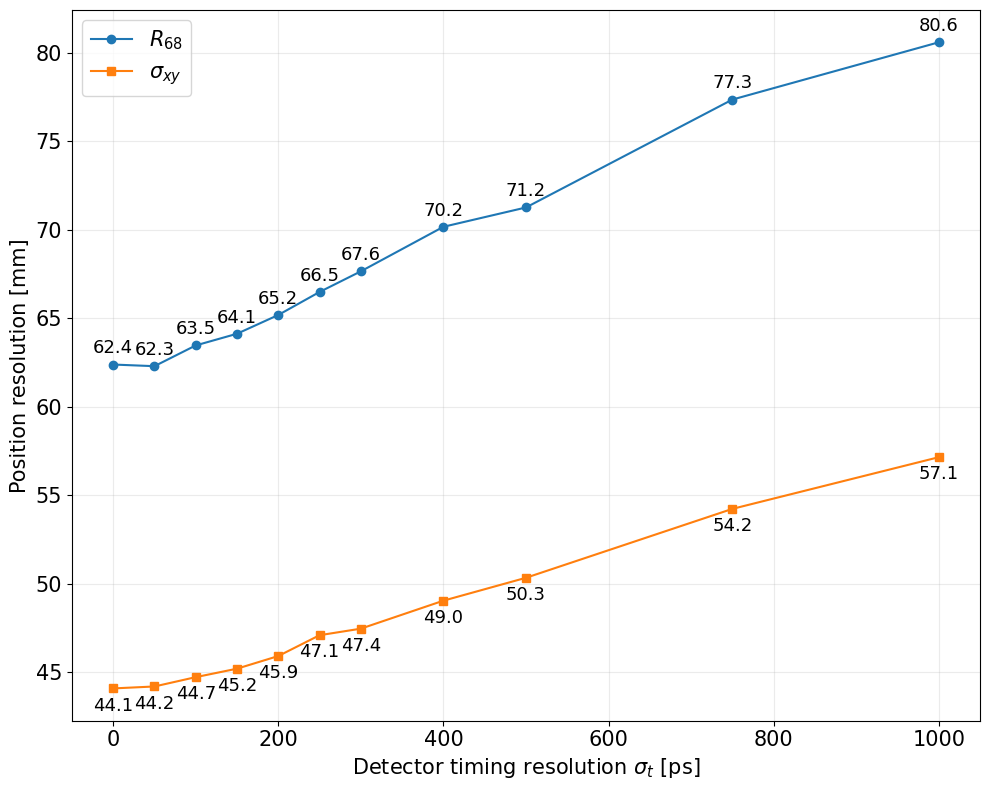

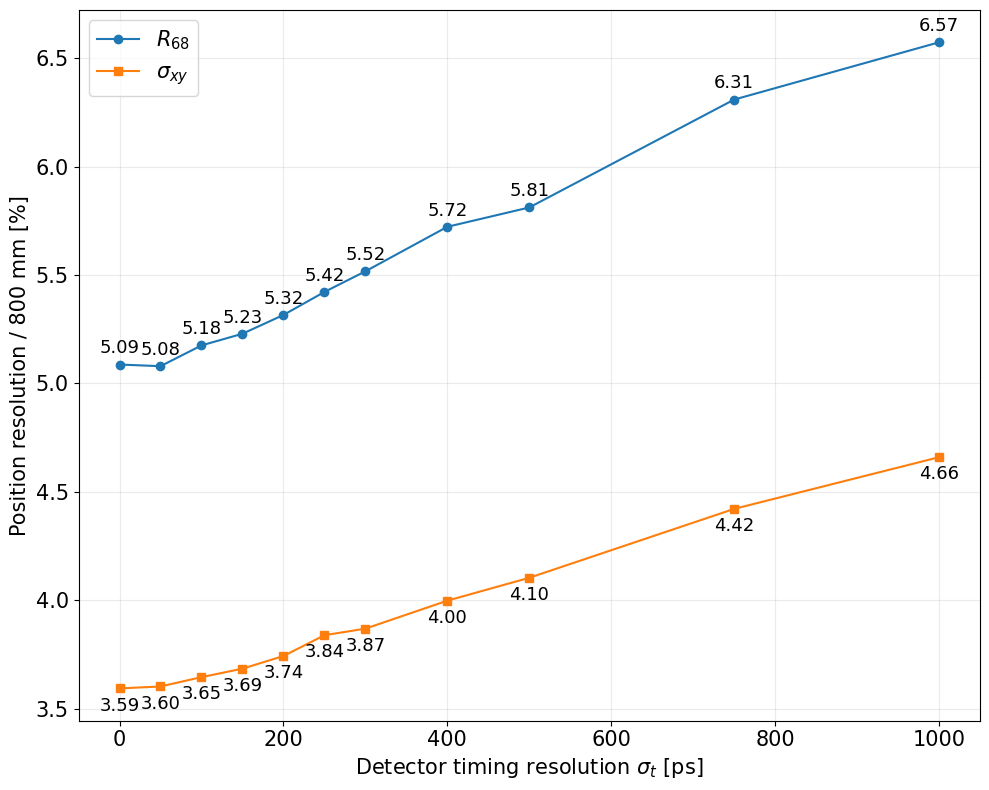

In [34]:
# Timing-resolution scan — hexagonal detector
fig,ax=plt.subplots(figsize=(10,8))
ax.plot(S.sigma_t_ps,S.R68_mm,"o-",label=r"$R_{68}$")
ax.plot(S.sigma_t_ps,S.sigma_xy_mm,"s-",label=r"$\sigma_{xy}$")

for x,y in zip(S.sigma_t_ps,S.R68_mm):
    ax.annotate(f"{y:.1f}",(x,y),(0,8),textcoords="offset points",ha="center",fontsize=13)
for x,y in zip(S.sigma_t_ps,S.sigma_xy_mm):
    ax.annotate(f"{y:.1f}",(x,y),(0,-16),textcoords="offset points",ha="center",fontsize=13)

ax.set(xlabel=r"Detector timing resolution $\sigma_t$ [ps]",
       ylabel="Position resolution [mm]")
ax.tick_params(labelsize=15)
ax.xaxis.label.set_size(15); ax.yaxis.label.set_size(15)
ax.grid(alpha=.25); ax.legend(fontsize=15)
plt.tight_layout(); plt.show()

S["R68_pct"]=100*S.R68_mm/LREF
S["sigma_pct"]=100*S.sigma_xy_mm/LREF

fig,ax=plt.subplots(figsize=(10,8))
ax.plot(S.sigma_t_ps,S.R68_pct,"o-",label=r"$R_{68}$")
ax.plot(S.sigma_t_ps,S.sigma_pct,"s-",label=r"$\sigma_{xy}$")

for x,y in zip(S.sigma_t_ps,S.R68_pct):
    ax.annotate(f"{y:.2f}",(x,y),(0,8),textcoords="offset points",ha="center",fontsize=13)
for x,y in zip(S.sigma_t_ps,S.sigma_pct):
    ax.annotate(f"{y:.2f}",(x,y),(0,-16),textcoords="offset points",ha="center",fontsize=13)

ax.set(xlabel=r"Detector timing resolution $\sigma_t$ [ps]",
       ylabel="Position resolution / 800 mm [%]")
ax.tick_params(labelsize=15)
ax.xaxis.label.set_size(15); ax.yaxis.label.set_size(15)
ax.grid(alpha=.25); ax.legend(fontsize=15)
plt.tight_layout(); plt.show()

## What to check first

- Confirm `NSIPM` and the inferred hexagon plot are correct.
- If you know the exact optical-contact coordinates of every SiPM, fill `SIPM_POS_MANUAL` before using the COG result as a true geometry-based COG comparison.
- For your main reconstruction comparison, focus first on **`A + t1+t2+t3 ExtraTrees`**, **`A + dN/dt HGB`**, and **Full ST Poisson**.
- Compare both $\sigma_{xy}$ and the radial containment metrics $R_{68}$/$R_{90}$; for a non-rectangular detector, $R_{68}$ is usually easier to interpret globally than only one projected residual width.
